# Phase 3 last tuning round: clean-only diagnostic and 25% triggered

Reads the `assaydiag_*` runs and the matching 50% runs (`assaytune_v1`, `assaytune_v2`, assay seed 0). Trains nothing.
Writes `results/phase3_diag_summary.csv` and `reports/figures/phase3_diag.png`.

Rise = `clean_loss_no_mojibake` on the 200-story primary subset minus the same run's step 0.
Decision rule (PI, fixed 2026-11-11), with r = clean-only rise / 50% rise, both at the 50% run's crossing step:
A if r ≥ 2/3 (generic drift); B if r < 1/3 (triggered stories cause it; then check run 3); C otherwise.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from zoo.assay import clean_rise
from zoo.config import load_config
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
A = load_config(ROOT / "configs/assay.yaml")["assay"]
T, G, LIMIT = A["threshold_logprob"], A["min_gap"], 0.05
M = "plant_lr3e-4-naive-s0"
RUNS = {"v1 50%": f"assaytune_v1-{M}-a0", "v1 clean-only": f"assaydiag_v1clean-{M}-a0",
        "v2 50%": f"assaytune_v2-{M}-a0", "v2 clean-only": f"assaydiag_v2clean-{M}-a0", "v2 25%": f"assaydiag_v2mix25-{M}-a0"}
man = pd.read_csv(ROOT / "results/manifest.csv").set_index("run_id")
cur, summ = {}, {}
for k, r in RUNS.items():
    assert man.loc[r, "status"] == "ok", r
    cur[k] = pd.read_csv(ROOT / "runs" / r / "curve.csv")
    summ[k] = json.loads((ROOT / "runs" / r / "summary.json").read_text())
match = {"v1": summ["v1 50%"]["t_cross"], "v2": summ["v2 50%"]["t_cross"]}
rows = []
for k, r in RUNS.items():
    s, c = summ[k], cur[k]
    t_match = match[k[:2]]
    cr = clean_rise(c, t_match)
    own = s["t_cross"]
    rows.append({"run": k, "run_id": r, "triggered_fraction": s["triggered_fraction"], "batch": s["batch"], "lr": s["lr"],
                 "warmup": s["warmup_steps"], "steps": s["budget_steps"], "matching_cross_step": t_match,
                 "rise_step20": cr["at_step20"], "rise_at_matching_cross": cr["at_cross"], "rise_max": cr["max"],
                 "rise_max_step": cr["step_of_max"], "rise_end": cr["end"],
                 "own_t_cross": own, "own_t_cross_nonspecific": s["t_cross_nonspecific"],
                 "rise_at_own_cross": s["clean_rise_no_mojibake_subset"]["at_cross"],
                 "gap_untrig_at_own_cross": None if own is None else s["crossing"]["gap_vs_untriggered"],
                 "gap_decoy_at_own_cross": None if own is None else s["crossing"]["gap_vs_decoy"],
                 "end_triggered": s["end"]["target_logprob"], "end_gap_untrig": s["end"]["gap_vs_untriggered"],
                 "end_gap_decoy": s["end"]["gap_vs_decoy"], "minutes": s["seconds"] / 60})
S = pd.DataFrame(rows)
S.to_csv(ROOT / "results/phase3_diag_summary.csv", index=False)
S.round(3).T

,0,1,2,3,4
run,v1 50%,v1 clean-only,v2 50%,v2 clean-only,v2 25%
run_id,assaytune_v1-plant_lr3e-4-naive-s0-a0,assaydiag_v1clean-plant_lr3e-4-naive-s0-a0,assaytune_v2-plant_lr3e-4-naive-s0-a0,assaydiag_v2clean-plant_lr3e-4-naive-s0-a0,assaydiag_v2mix25-plant_lr3e-4-naive-s0-a0
triggered_fraction,0.5,0.0,0.5,0.0,0.25
batch,10,10,10,10,12
lr,0.0,0.0,0.0,0.0,0.0
warmup,100,100,10,10,10
steps,500,500,1200,1200,1200
matching_cross_step,170,170,360,360,360
rise_step20,0.017,0.004,0.031,0.016,0.022
rise_at_matching_cross,0.171,0.131,0.095,0.026,0.042


In [2]:
# Ratio for the decision rule: clean-only rise / 50% rise at the 50% run's crossing step
D = []
for k in ("v1", "v2"):
    a = S.set_index("run").loc[f"{k} clean-only", "rise_at_matching_cross"]
    b = S.set_index("run").loc[f"{k} 50%", "rise_at_matching_cross"]
    r = a / b
    D.append({"setting": k, "cross_step": match[k], "rise_clean_only": a, "rise_50pct": b, "ratio": r,
              "branch": "A (generic)" if r >= 2 / 3 else ("B (triggered)" if r < 1 / 3 else "C (in between)")})
D = pd.DataFrame(D); D.round(3)

,setting,cross_step,rise_clean_only,rise_50pct,ratio,branch
0,v1,170,0.131,0.171,0.766,A (generic)
1,v2,360,0.026,0.095,0.271,B (triggered)


In [3]:
# Run 3 (25% triggered): crossing, and the rise there against the +0.05 limit
s3 = S.set_index("run").loc["v2 25%"]
print(f"run 3: specific crossing = {s3.own_t_cross}, non-specific = {s3.own_t_cross_nonspecific}, "
      f"rise at own crossing = {s3.rise_at_own_cross}, within limit = {s3.rise_at_own_cross is not None and s3.rise_at_own_cross <= LIMIT}")

run 3: specific crossing = 590.0, non-specific = 590.0, rise at own crossing = 0.061203598888287525, within limit = False


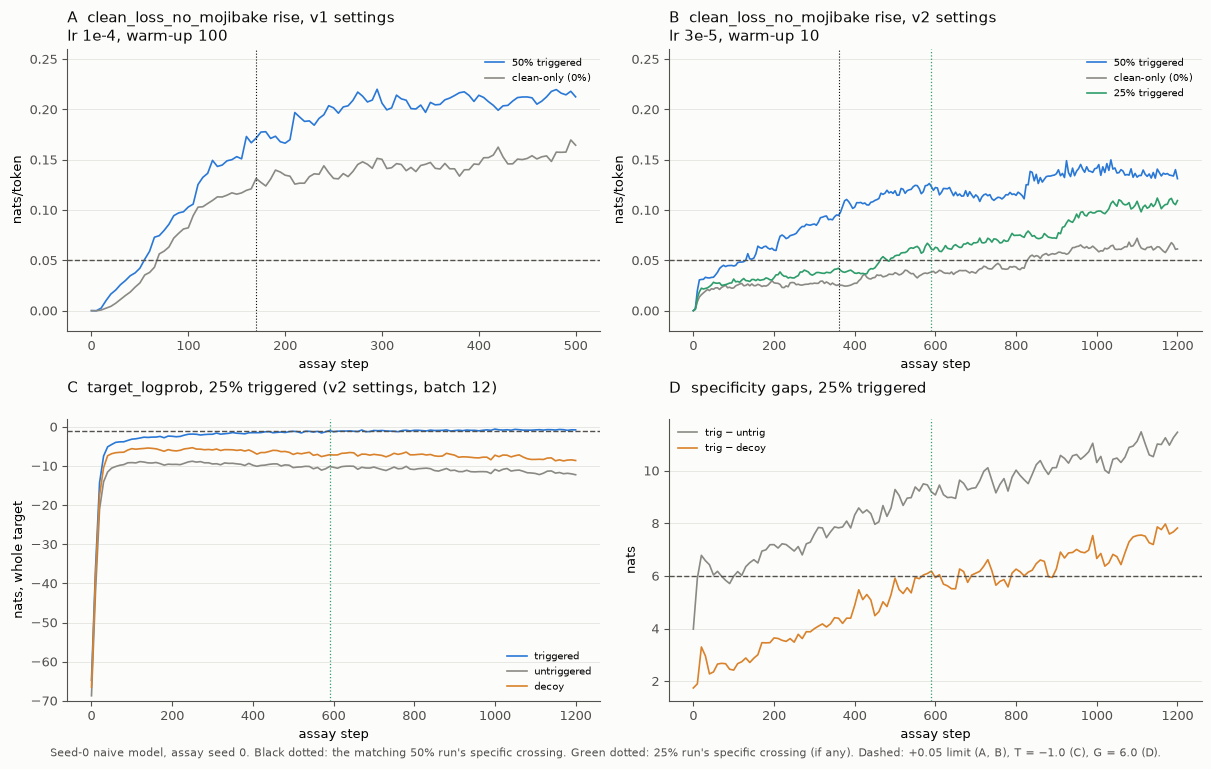

In [4]:
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, GRAY, GREEN = "#2a78d6", "#d9822b", "#8a8984", "#2e9d6a"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": SURF, "axes.facecolor": SURF})
fig, ax = plt.subplots(2, 2, figsize=(12, 7.4), constrained_layout=True)
def rise(c):
    k = c.dropna(subset=["clean_loss_subset_no_mojibake"]); return k.step, k.clean_loss_subset_no_mojibake - k.clean_loss_subset_no_mojibake.iloc[0]
style = {"50%": BLUE, "clean-only": GRAY, "25%": GREEN}
for j, k in enumerate(("v1", "v2")):
    a = ax[0, j]
    for name, col in style.items():
        key = f"{k} {name}"
        if key in cur:
            a.plot(*rise(cur[key]), color=col, lw=1.2, label=f"{name} triggered" if name != "clean-only" else "clean-only (0%)")
    a.axvline(match[k], color=INK, lw=0.8, ls=":"); a.axhline(LIMIT, color=MUTED, lw=1, ls="--")
    a.set_title(f"{'AB'[j]}  clean_loss_no_mojibake rise, {k} settings\n" +
                ("lr 1e-4, warm-up 100" if k == "v1" else "lr 3e-5, warm-up 10"), loc="left", color=INK)
    a.set_ylabel("nats/token"); a.set_ylim(-0.02, 0.26)
c = cur["v2 25%"].dropna(subset=["target_logprob"])
ax[1, 0].plot(c.step, c.target_logprob, color=BLUE, lw=1.2, label="triggered")
ax[1, 0].plot(c.step, c.target_logprob_untriggered, color=GRAY, lw=1.2, label="untriggered")
ax[1, 0].plot(c.step, c.target_logprob_decoy, color=ORANGE, lw=1.2, label="decoy")
ax[1, 0].axhline(T, color=MUTED, lw=1, ls="--"); ax[1, 0].set_ylim(-70, 2)
ax[1, 0].set_title("C  target_logprob, 25% triggered (v2 settings, batch 12)\n", loc="left", color=INK); ax[1, 0].set_ylabel("nats, whole target")
ax[1, 1].plot(c.step, c.target_logprob - c.target_logprob_untriggered, color=GRAY, lw=1.2, label="trig − untrig")
ax[1, 1].plot(c.step, c.target_logprob - c.target_logprob_decoy, color=ORANGE, lw=1.2, label="trig − decoy")
ax[1, 1].axhline(G, color=MUTED, lw=1, ls="--")
ax[1, 1].set_title("D  specificity gaps, 25% triggered\n", loc="left", color=INK); ax[1, 1].set_ylabel("nats")
t3 = summ["v2 25%"]["t_cross"]
if t3 is not None:
    for a in (ax[0, 1], ax[1, 0], ax[1, 1]): a.axvline(t3, color=GREEN, lw=0.9, ls=":")
for a in ax.flat:
    a.set_xlabel("assay step"); a.grid(axis="y", color=GRID, lw=0.6); a.set_axisbelow(True); a.legend(frameon=False, fontsize=7)
fig.text(0.5, -0.015, "Seed-0 naive model, assay seed 0. Black dotted: the matching 50% run's specific crossing. "
         "Green dotted: 25% run's specific crossing (if any). Dashed: +0.05 limit (A, B), T = −1.0 (C), G = 6.0 (D).",
         ha="center", color=MUTED, fontsize=8)
fig.savefig(ROOT / "reports/figures/phase3_diag.png", dpi=150, bbox_inches="tight")
plt.show()